# YARDI Data EDA

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

## Load Parquets

In [2]:
#read in datasets
property_df = pd.read_parquet("/Users/njlim21/Desktop/forty5park/vignette/01_geospatial_expansion/data/042026-property-enriched-12060.parquet")
unit_mix_df = pd.read_parquet("/Users/njlim21/Desktop/forty5park/vignette/01_geospatial_expansion/data/042026-unit-mix-enriched-12060.parquet")
rent_df = pd.read_parquet("/Users/njlim21/Desktop/forty5park/vignette/01_geospatial_expansion/data/042026-rent-12060.parquet")
hist_rent_df = pd.read_parquet("/Users/njlim21/Desktop/forty5park/vignette/01_geospatial_expansion/data/042026-hist-rent-12060-12060.parquet")

for name, df in (
    ("property-enriched", property_df),
    ("unit-mix-enriched", unit_mix_df),
    ("rent", rent_df),
    ("hist-rent", hist_rent_df),
):
    print(f"\n\033[1m{name}:\033[0m\n")
    display(df.head())


property-enriched:



,market,sub_market,source_name,source_property_id,is_yardi_btr,property_name,street_address,city,state,zipcode,...,is_yardi_unittype_btr,property_average_rent,property_average_rent_sqft,latest_sale_date,latest_sale_price_date,latest_sale_price_per_sqft,latest_sale_price_per_unit,latest_sale_price_total,owner_name,date
0,Atlanta - Suburban,1 - Sandy Springs,yardi,24_1345530,False,ARIUM Morgan Falls,8085 Adair Lane,Sandy Springs,GA,30350,...,False,1377.916992,1.445196,2020-10-20,2020-10-20,141.610001,132288.140625,156100000.0,"RMR Group, The",2026-04-20
1,Atlanta - Suburban,1 - Sandy Springs,yardi,24_1534244,True,Ellison Park,400 Hanover Park Road,Sandy Springs,GA,30350,...,True,3587.641846,1.430535,2021-04-14,None,NaN,NaN,NaN,RSE Capital Partners,2026-04-20
2,Atlanta - Suburban,1 - Sandy Springs,yardi,24_2119,False,Highland Park,100 Highland Park Trail,Atlanta,GA,30350,...,False,1938.638306,1.605826,2015-09-29,2015-09-29,113.110001,139361.703125,26200000.0,EEA Realty,2026-04-20
3,Atlanta - Suburban,1 - Sandy Springs,yardi,24_2291,False,Waters Edge,8601 Roberts Drive,Sandy Springs,GA,30350,...,False,1439.769287,1.500713,2022-04-25,2022-04-25,196.100006,194230.765625,40400000.0,McDowell Properties,2026-04-20
4,Atlanta - Suburban,1 - Sandy Springs,yardi,24_2347,False,"Edgewater at Sandy Springs, The",7600 Roswell Road,Atlanta,GA,30350,...,False,1297.168457,1.350429,2019-09-12,2019-09-12,132.869995,133223.687500,101250000.0,Bridge Investment Group,2026-04-20



unit-mix-enriched:



,source_property_id,unit_type,unit_configuration,has_direct_access_garage,num_units,living_area_square_feet,number_of_bedrooms,number_of_full_baths,rent_close_date,rent_amount,haystacks_unit_type,date
0,22_1004844,Apartment,1BR,False,186,685,1,1,2026-03-01,1657.096802,APARTMENT,2026-04-20
1,22_1004844,Apartment,2BR/1Bath,False,36,890,2,1,2026-03-01,1775.000000,APARTMENT,2026-04-20
2,22_1004844,Apartment,2BR/2Bath,False,108,1090,2,2,2026-03-01,1889.500000,APARTMENT,2026-04-20
3,22_1004844,Apartment,3BR+,False,36,1275,3,2,2026-03-01,2055.500000,APARTMENT,2026-04-20
4,22_1004845,Apartment,1BR,False,96,840,1,1,2026-03-01,1690.000000,APARTMENT,2026-04-20



rent:



,property_id,unit_mix_type,unit_garage,unit_type,period,rent,date
0,22_1004844,Apartment,0,1BR,2026-03-01,1657.096802,2026-04-20
1,22_1004844,Apartment,0,2BR/1Bath,2026-03-01,1775.000000,2026-04-20
2,22_1004844,Apartment,0,2BR/2Bath,2026-03-01,1889.500000,2026-04-20
3,22_1004844,Apartment,0,3BR+,2026-03-01,2055.500000,2026-04-20
4,22_1004845,Apartment,0,1BR,2026-03-01,1690.000000,2026-04-20



hist-rent:



,property_id,unit_mix_type,unit_garage,unit_type,period,rent,date
0,22_1004844,None,NaN,1BR,2015-01-01,1080.774170,2026-04-20
1,22_1004844,None,NaN,1BR,2015-02-01,1138.064575,2026-04-20
2,22_1004844,None,NaN,1BR,2015-03-01,1127.903198,2026-04-20
3,22_1004844,None,NaN,1BR,2015-04-01,1117.741943,2026-04-20
4,22_1004844,None,NaN,1BR,2015-05-01,1107.580688,2026-04-20


In [3]:
#print shape and info (col names, number of nulls, col types) 
for name, df in (
    ("property-enriched", property_df),
    ("unit-mix-enriched", unit_mix_df),
    ("rent", rent_df),
    ("hist-rent", hist_rent_df),
):
    print(f"\033[1m{name}:\033[0m\n  shape: {df.shape}\n")
    print(f"  info:")
    print(f"{df.info()}\n\n\n")

property-enriched:
  shape: (2121, 59)

  info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 59 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   market                      2121 non-null   object  
 1   sub_market                  2121 non-null   object  
 2   source_name                 2121 non-null   object  
 3   source_property_id          2121 non-null   object  
 4   is_yardi_btr                2121 non-null   bool    
 5   property_name               2121 non-null   object  
 6   street_address              2121 non-null   object  
 7   city                        2121 non-null   object  
 8   state                       2121 non-null   object  
 9   zipcode                     2121 non-null   object  
 10  longitude                   2121 non-null   float32 
 11  latitude                    2121 non-null   float32 
 12  num_units                   

## Missing Data

In [4]:
#most missing data is in the property enriched parquet
#print top ten columns with most null values
top_missing_cols = (property_df.isna().mean() * 100).sort_values(ascending=False)
print("\n\033[1m% of data that is missing in each column:\033[0m")
top_missing_cols.head(10)


% of data that is missing in each column:


garage                        85.667138
has_media_room                68.081094
covered_parking               36.209335
latest_sale_price_per_unit    28.995757
latest_sale_price_per_sqft    28.995757
latest_sale_price_total       28.901462
latest_sale_price_date        28.901462
latest_sale_date              24.846770
occupancy_date                 7.072136
occupancy_rate                 7.072136
dtype: float64

In [5]:
#explore the top 3 cols
for col in [
    'garage', 
    'has_media_room', 
    'covered_parking', 
]:
    print(f"{property_df[col].value_counts(dropna=False)}\n")

garage
None             1817
Direct Access     275
Free Standing      23
Both                6
Name: count, dtype: int64

has_media_room
None     1444
False     583
True       94
Name: count, dtype: int64

covered_parking
None       1093
None        768
Partial     190
All          70
Name: count, dtype: int64



In [6]:
property_df['has_garage'].value_counts()[False] == property_df['garage'].isna().sum()
#number of null values in 'garage' equals the number of Falses in 'has_garage' --> 1817

True

  
Solutions for these null-heavy columns:  
**garage**: A null value in this column means that property has no garage; replace the null values with the string 'None' and can use dummy encoding to change the values to integers.  
**has_media_room**: Can assume the null values indicate no media room in the property; replace the null values with False (bool).  
**covered_parking**: There are both None (null type) and 'None' (string type) values in this col; can assume they both imply no covered parking.

## Cardinality of Object Cols

In [7]:
#number of unique values for every object type col
for name, df in (
    ("property-enriched", property_df),
    ("unit-mix-enriched", unit_mix_df),
    ("rent", rent_df),
    ("hist-rent", hist_rent_df),
):
    print(f"\033[1m{name}:\033[0m\n{df.select_dtypes('object').nunique()}\n")

property-enriched:
market                       2
sub_market                  74
source_name                  1
source_property_id        2121
property_name             2106
street_address            2115
city                        79
state                        1
zipcode                    146
property_quality             9
location_quality            10
website                   1969
has_controlled_access        2
has_fitness_center           2
has_business_center          2
has_clubhouse                2
covered_parking              3
garage                       3
parking_type                 5
rent_office                  3
has_media_room               2
is_elevator_served           2
wd_hookup                    3
wd_in_unit                   3
county                      23
parcel_complete           2113
is_mixed_use                 2
occupancy_date               1
census_cbsa_geoid            1
census_zcta5_geoid         148
census_tract_geoid         795
unit_mix            

In [8]:
#drop cols that are irrelevant (ex: cols with only one unique value, cols with unique value for almost every row)
drop_cols_1 = [
    'source_name', 'source_property_id', 'property_name', 'street_address', 'state', 'website', 'parcel_complete', 'occupancy_date',
    'census_cbsa_geoid', 'unit_mix', 'latest_sale_date', 'latest_sale_price_date', 'owner_name'
]
drop_cols_2 = [
    'source_property_id', 'rent_close_date' 
]

for name, df in (
    ("property-enriched", property_df),
    ("unit-mix-enriched", unit_mix_df),
    #removed rent and hist_rent since it contains identical cols as unit_mix
):
    if df.equals(property_df):
        print(f"\033[1m{name}:\033[0m\n{df.drop(columns=drop_cols_1).select_dtypes('object').nunique()}\n")
    elif df.equals(unit_mix_df):
        print(f"\033[1m{name}:\033[0m\n{df.drop(columns=drop_cols_2).select_dtypes('object').nunique()}\n")

property-enriched:
market                     2
sub_market                74
city                      79
zipcode                  146
property_quality           9
location_quality          10
has_controlled_access      2
has_fitness_center         2
has_business_center        2
has_clubhouse              2
covered_parking            3
garage                     3
parking_type               5
rent_office                3
has_media_room             2
is_elevator_served         2
wd_hookup                  3
wd_in_unit                 3
county                    23
is_mixed_use               2
census_zcta5_geoid       148
census_tract_geoid       795
dtype: int64

unit-mix-enriched:
unit_type              8
unit_configuration     5
haystacks_unit_type    5
dtype: int64



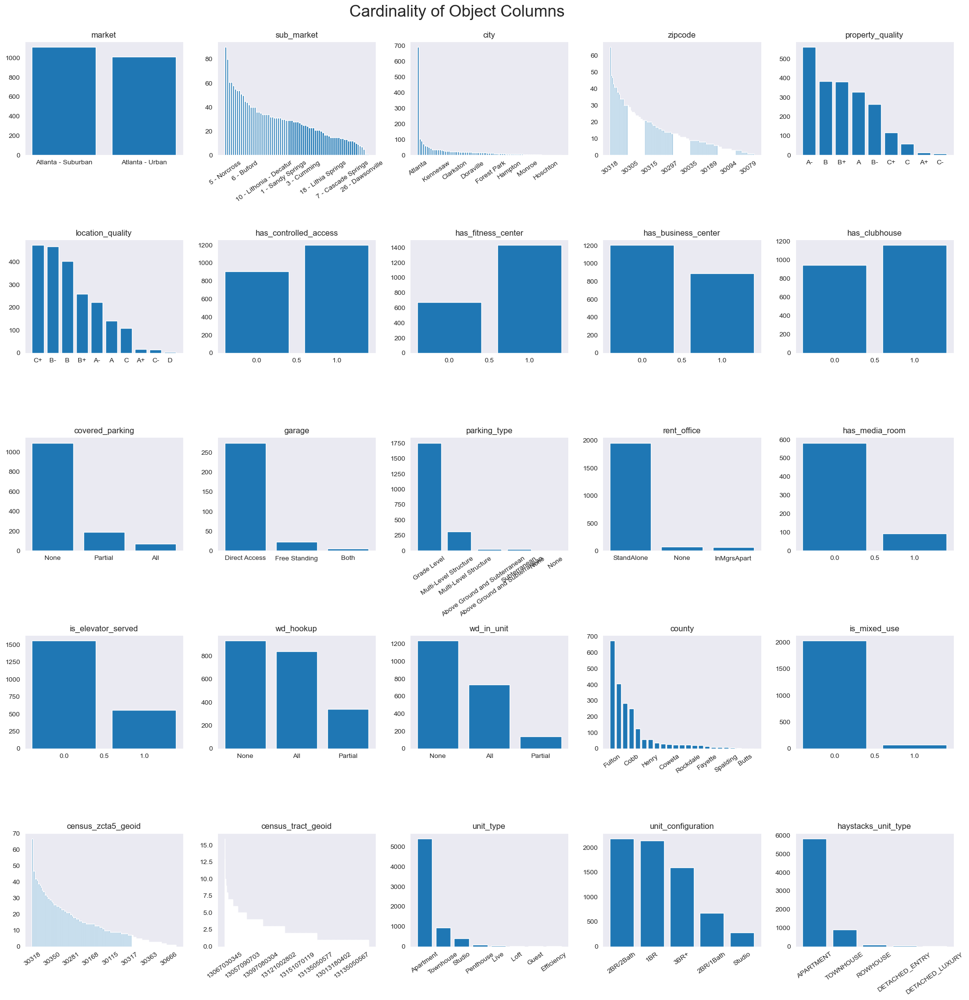

In [9]:
from matplotlib.ticker import MaxNLocator
sns.set_style('dark')

#get all relevant object col names in a list
property_obj_cols = property_df.drop(columns=drop_cols_1).select_dtypes('object').columns.tolist()
unitmix_obj_cols = unit_mix_df.drop(columns=drop_cols_2).select_dtypes('object').columns.tolist()

#plot frequency of unqiue values for every object col
fig, axes = plt.subplots(5, 5, figsize=(20, 20))
axes_flat = axes.flatten()
for i, col in enumerate(property_obj_cols):
    ax = axes_flat[i]
    #deal with plots with large number of xlabels
    if property_df[col].nunique() > 10 or col == 'parking_type':
        ax.bar(x=property_df[col].value_counts().index, height=property_df[col].value_counts().values)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=9)) 
        ax.tick_params(axis='x', rotation=35)
    else:
        ax.bar(x=property_df[col].value_counts().index, height=property_df[col].value_counts().values)
    ax.set_title(f"{col}")

#repeat for unit_mix_df
for i, col in enumerate(unitmix_obj_cols):
    ax = axes_flat[i+len(property_obj_cols)]
    ax.bar(x=unit_mix_df[col].value_counts().index, height=unit_mix_df[col].value_counts().values)
    ax.tick_params(axis='x', rotation=35)
    ax.set_title(f"{col}")

plt.tight_layout()
fig.suptitle("Cardinality of Object Columns", x=0.47, y=1.02, fontsize=24)
plt.show()

## Target Variable: Rent

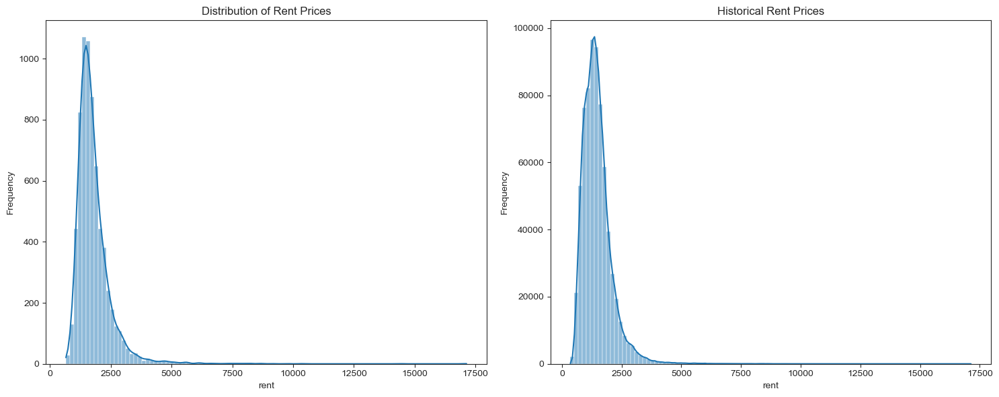

In [10]:
#instantiate/explore response variable
y = rent_df['rent']
y_hist = hist_rent_df['rent']

#plot
sns.set_style('ticks')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.histplot(data=rent_df, x=y, bins=100, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Rent Prices")

sns.histplot(data=hist_rent_df, x=y_hist, bins=100, kde=True, ax=axes[1])
axes[1].set_title("Historical Rent Prices")

for ax in axes.flat:
    ax.set_ylabel("Frequency")
    
plt.tight_layout()
plt.show()

Target variable data is heavily right skewed.


Number of outliters: 343
Outlier percentage: 0.049775068930489046


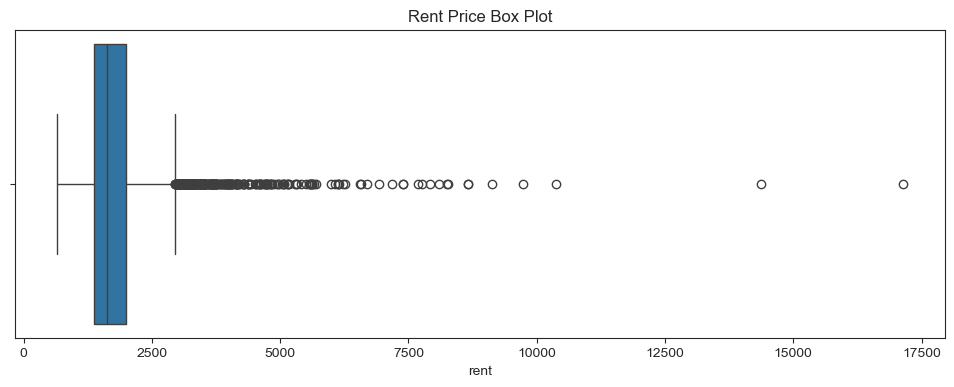

In [11]:
#check for outliers in rent prices
#box and whisker plot to check for outliers
fig, axes = plt.subplots(figsize=(12, 4))
sns.boxplot(data=rent_df, x=y, ax=axes)
axes.set_title('Rent Price Box Plot')
plt.plot()

Q_one = y.quantile(0.25)
Q_three = y.quantile(0.75)
IQR = Q_three - Q_one
lower_bound = Q_one - (IQR * 1.5)
upper_bound = Q_three + (IQR * 1.5)

outliers_count = ((y > upper_bound) | (y < lower_bound)).sum()
print("\nNumber of outliters: " + str(outliers_count))
print("Outlier percentage: " + str(outliers_count / len(y)))

Solution to skewed data with a good amount of outliers: **apply log transformation to the rent prices**

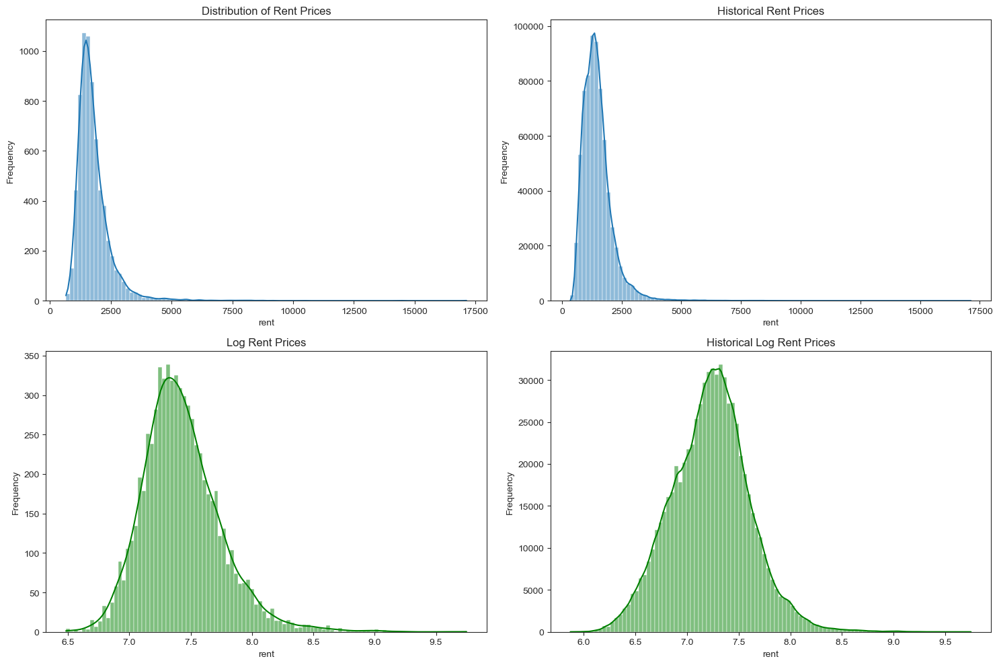

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(data=rent_df, x=y, bins=100, kde=True, ax=axes[0][0])
axes[0][0].set_title("Distribution of Rent Prices")

sns.histplot(data=hist_rent_df, x=y_hist, bins=100, kde=True, ax=axes[0][1])
axes[0][1].set_title("Historical Rent Prices")


#plot log-scaled data
y_log = np.log1p(rent_df['rent'])
y_hist_log = np.log1p(hist_rent_df['rent'])

sns.histplot(data=rent_df, x=y_log, bins=100, color='g', kde=True, ax=axes[1][0])
axes[1][0].set_title("Log Rent Prices")

sns.histplot(data=hist_rent_df, x=y_hist_log, bins=100, color='g', kde=True, ax=axes[1][1])
axes[1][1].set_title("Historical Log Rent Prices")
for ax in axes.flat:
    ax.set_ylabel("Frequency")
    
plt.tight_layout()
plt.show()


Number of outliters: 166
Outlier percentage: 0.024089391960528225


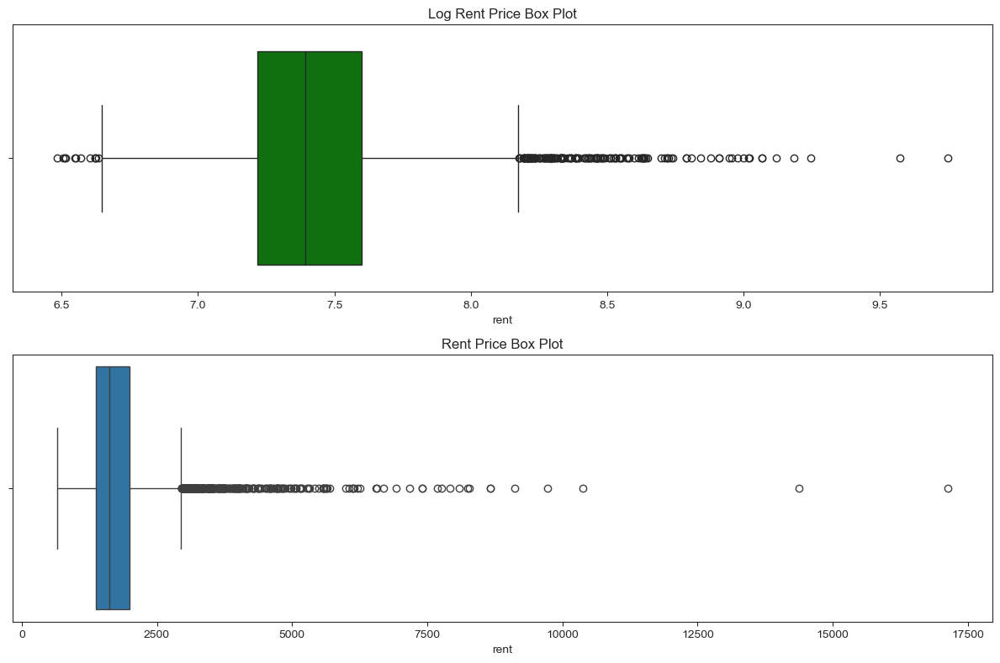

In [13]:
#box and whisker plot for log rent
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
sns.boxplot(data=rent_df, x=y_log, ax=axes[0], color='g')
axes[0].set_title('Log Rent Price Box Plot')

sns.boxplot(data=rent_df, x=y, ax=axes[1])
axes[1].set_title('Rent Price Box Plot')
plt.tight_layout()
plt.plot()

Q_one_log = y_log.quantile(0.25)
Q_three_log = y_log.quantile(0.75)
IQR_log = Q_three_log - Q_one_log
lower_bound_log = Q_one_log - (IQR_log * 1.5)
upper_bound_log = Q_three_log + (IQR_log * 1.5)

outliers_count_log = ((y_log > upper_bound_log) | (y_log < lower_bound_log)).sum()
print("\nNumber of outliters: " + str(outliers_count_log))
print("Outlier percentage: " + str(outliers_count_log / len(y_log)))

## Relationships between Rent Price and Variables  
1. Rent vs. Property Characteristics
2. Rent vs. Amenities
3. Rent vs. Geographical Data

In [14]:
#join rent_df and unit_mix_df parquets into one
rent_df['unit_garage'] = rent_df['unit_garage'].astype(bool)
combined_df = pd.merge(
    rent_df, unit_mix_df, how='left', 
        left_on=['property_id', 'unit_type', 'unit_mix_type', 'unit_garage'], 
        right_on=['source_property_id', 'unit_configuration', 'unit_type', 'has_direct_access_garage'])

#join resulting parquet with property_df
combined_df = pd.merge(
    combined_df, property_df, how='left', on='source_property_id')

#check if rent column is preserved
print(rent_df['rent'].equals(combined_df['rent']))
print("\n")

combined_df

True




,property_id,unit_mix_type,unit_garage,unit_type_x,period,rent,date_x,source_property_id,unit_type_y,unit_configuration,...,is_yardi_unittype_btr,property_average_rent,property_average_rent_sqft,latest_sale_date,latest_sale_price_date,latest_sale_price_per_sqft,latest_sale_price_per_unit,latest_sale_price_total,owner_name,date
0,22_1004844,Apartment,False,1BR,2026-03-01,1657.096802,2026-04-20,22_1004844,Apartment,1BR,...,False,1776.458984,2.095651,2018-09-28,2018-09-28,197.960007,176601.09375,64636000.0,Olen Properties,2026-04-20
1,22_1004844,Apartment,False,2BR/1Bath,2026-03-01,1775.000000,2026-04-20,22_1004844,Apartment,2BR/1Bath,...,False,1776.458984,2.095651,2018-09-28,2018-09-28,197.960007,176601.09375,64636000.0,Olen Properties,2026-04-20
2,22_1004844,Apartment,False,2BR/2Bath,2026-03-01,1889.500000,2026-04-20,22_1004844,Apartment,2BR/2Bath,...,False,1776.458984,2.095651,2018-09-28,2018-09-28,197.960007,176601.09375,64636000.0,Olen Properties,2026-04-20
3,22_1004844,Apartment,False,3BR+,2026-03-01,2055.500000,2026-04-20,22_1004844,Apartment,3BR+,...,False,1776.458984,2.095651,2018-09-28,2018-09-28,197.960007,176601.09375,64636000.0,Olen Properties,2026-04-20
4,22_1004845,Apartment,False,1BR,2026-03-01,1690.000000,2026-04-20,22_1004845,Apartment,1BR,...,False,1889.268921,1.903688,2018-09-28,2018-09-28,195.619995,195378.15625,46500000.0,Olen Properties,2026-04-20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6886,24_99,Apartment,False,1BR,2026-03-01,1467.444458,2026-04-20,24_99,Apartment,1BR,...,False,1609.543945,1.450172,2023-06-20,2023-06-20,141.899994,160000.00000,40000000.0,"Furman, Jeremy S.",2026-04-20
6887,24_99,Apartment,False,2BR/2Bath,2026-03-01,1582.850464,2026-04-20,24_99,Apartment,2BR/2Bath,...,False,1609.543945,1.450172,2023-06-20,2023-06-20,141.899994,160000.00000,40000000.0,"Furman, Jeremy S.",2026-04-20
6888,24_99,Apartment,False,3BR+,2026-03-01,1865.000000,2026-04-20,24_99,Apartment,3BR+,...,False,1609.543945,1.450172,2023-06-20,2023-06-20,141.899994,160000.00000,40000000.0,"Furman, Jeremy S.",2026-04-20
6889,24_99,Apartment,True,1BR,2026-03-01,1508.000000,2026-04-20,24_99,Apartment,1BR,...,False,1609.543945,1.450172,2023-06-20,2023-06-20,141.899994,160000.00000,40000000.0,"Furman, Jeremy S.",2026-04-20


### Property Characteristics

,count,mean,std,min,25%,median,75%,max
unit_configuration,,,,,,,,
3BR+,1596.0,2233.663330,980.479309,937.0,1713.750000,2025.239746,2436.002563,17129.833984
2BR/2Bath,2186.0,1892.084595,722.652344,750.0,1474.300934,1725.000000,2099.404968,14370.571289
1BR,2143.0,1489.127197,421.822479,653.0,1215.152161,1426.000000,1651.000000,5160.000000
2BR/1Bath,676.0,1470.019775,390.331482,737.0,1235.092468,1397.500000,1589.875000,5655.000000
Studio,286.0,1393.765137,388.912872,667.0,1111.750000,1397.166687,1605.293518,3087.500000


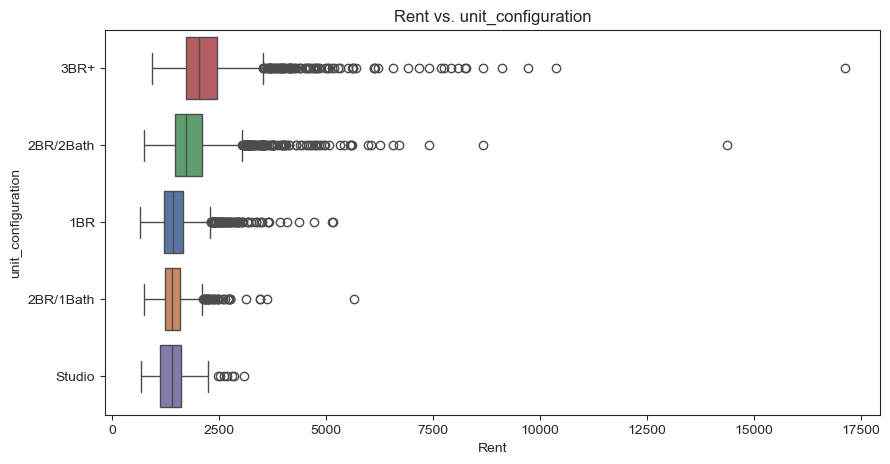

In [15]:
#create boxplot function
def boxplot(col):
    sum_stats = combined_df.groupby(col)['rent'].describe().sort_values(by='50%', ascending=False)
    sum_stats.rename(
        columns={'50%': 'median'}, inplace=True)
    display(sum_stats)
    
    sorted_cols = combined_df.groupby(col)['rent'].median().sort_values(ascending=False).index
    sns.boxplot(
        data=combined_df, y=col, x='rent', order=sorted_cols, hue=col, palette='deep', legend=False)

    plt.title("Rent vs. " + col)
    plt.ylabel(col)
    plt.xticks(rotation=0)
    plt.xlabel("Rent")
    plt.show()


#rent price vs. unit configuration
plt.figure(figsize=(10, 5))
boxplot('unit_configuration')

,count,mean,std,min,25%,median,75%,max
unit_mix_type,,,,,,,,
Penthouse,89.0,4661.824219,2611.031982,1702.000000,2925.833252,3910.399902,5592.904785,17129.833984
Live,25.0,2780.844482,942.220825,1471.000000,2202.000000,2689.666748,2912.000000,5655.000000
Guest,4.0,1767.500000,446.630707,1127.000000,1692.500000,1888.500000,1963.500000,2166.000000
Townhouse,946.0,2005.886841,756.930298,813.529419,1470.750000,1852.500000,2364.649902,7925.125000
Apartment,5419.0,1718.452148,569.136963,653.000000,1351.446045,1604.100952,1937.270264,9121.000000
Studio,393.0,1444.798340,343.719940,667.000000,1240.000000,1454.000000,1658.923096,3087.500000
Loft,8.0,1512.775391,601.426208,994.000000,1084.000000,1440.136353,1562.840698,2849.000000
Efficiency,3.0,1103.666626,297.002258,806.000000,955.500000,1105.000000,1252.500000,1400.000000


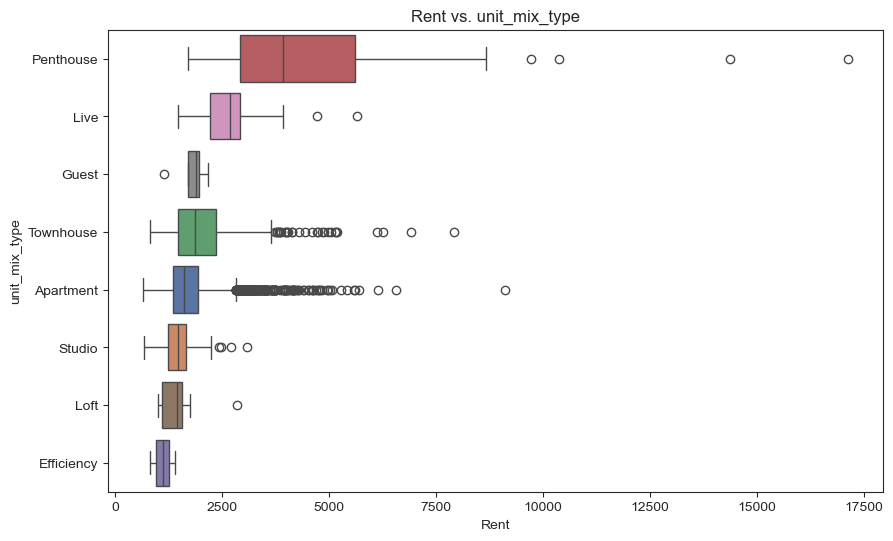

In [16]:
#rent price vs. unit type
plt.figure(figsize=(10, 6))
boxplot('unit_mix_type')

,count,mean,std,min,25%,median,75%,max
num_bedrooms,,,,,,,,
3.0,1596.0,2233.663330,980.479309,937.0,1713.75,2025.239746,2436.002563,17129.833984
2.0,2862.0,1792.393433,683.321411,737.0,1395.00,1641.035706,1984.417664,14370.571289
1.0,2429.0,1477.898926,419.134613,653.0,1207.00,1421.810791,1649.632080,5160.000000
nan,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


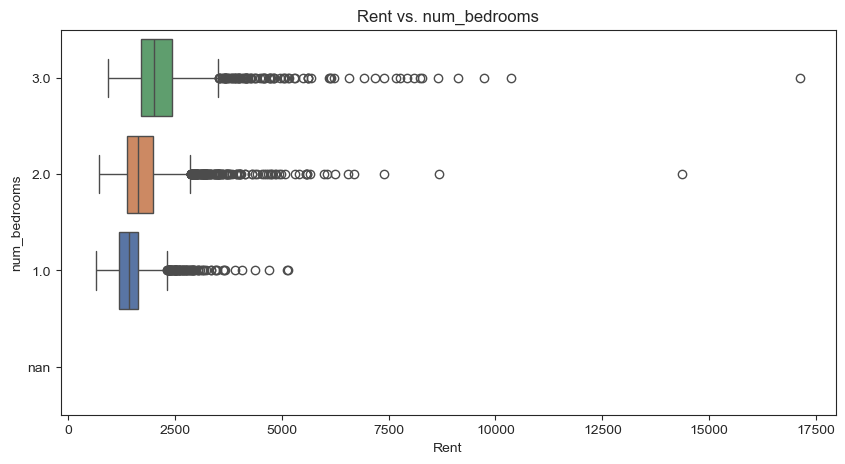

In [17]:
#rent price vs. number of bedrooms
plt.figure(figsize=(10, 5))
combined_df = combined_df.assign(num_bedrooms=combined_df['number_of_bedrooms'].astype(str))
boxplot('num_bedrooms')

,count,mean,std,min,25%,median,75%,max
num_bathrooms,,,,,,,,
2.0,3782.0,2036.230347,857.783020,750.0,1550.00,1852.750000,2259.387024,17129.833984
1.0,2819.0,1484.545288,414.501526,653.0,1223.00,1415.474731,1640.531860,5655.000000
0.0,286.0,1393.765137,388.912872,667.0,1111.75,1397.166687,1605.293518,3087.500000
nan,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


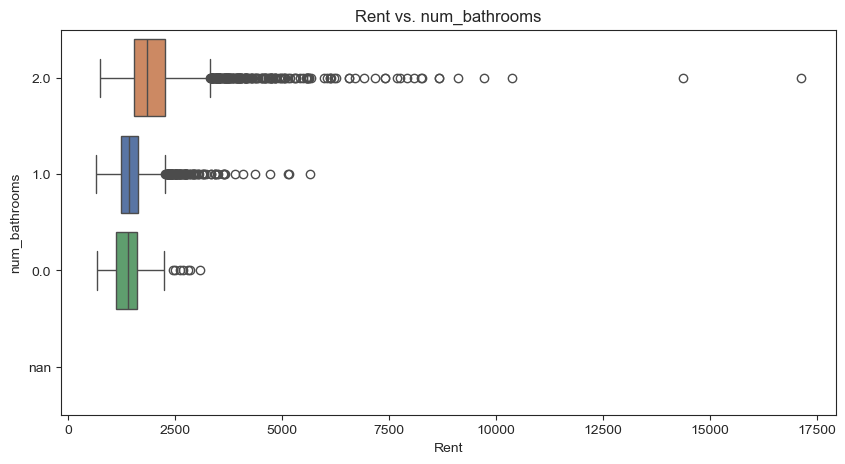

In [18]:
#rent price vs. number of full bathrooms
plt.figure(figsize=(10, 5))
combined_df = combined_df.assign(num_bathrooms=combined_df['number_of_full_baths'].astype(str))
boxplot('num_bathrooms')

combined_df = combined_df.drop(columns=['num_bedrooms', 'num_bathrooms'])

,count,mean,std,min,25%,median,75%,max
sub_market,,,,,,,,
28 - Haynes Manor/Peachtree Hills,43.0,3380.587891,3057.160889,1099.000000,1880.008667,2511.588135,3600.136353,17129.833984
22 - Midtown,58.0,2922.055664,1361.888794,1092.000000,2057.198547,2508.906982,3665.642883,7683.000000
17 - Inman Park/Virginia Highlands,63.0,2537.533936,929.594543,1129.000000,1735.010986,2449.428467,3156.099976,5655.000000
15 - Midtown South,136.0,2829.179932,1601.627075,1005.067749,1803.500000,2398.588989,3207.000000,10370.333008
16 - Martin Luther King Historic District,99.0,2604.086426,1290.701904,1115.947021,1875.028687,2184.000000,2941.546265,9730.000000
...,...,...,...,...,...,...,...,...
7 - Cascade Springs,33.0,1197.841309,205.315521,802.000000,1030.000000,1221.000000,1370.000000,1557.000000
8 - Oakland,41.0,1177.039673,200.539490,673.000000,1046.000000,1152.073120,1305.000000,1582.000000
4 - Forest Park,35.0,1172.304565,194.458389,916.090881,1034.574829,1149.000000,1246.000000,1830.000000


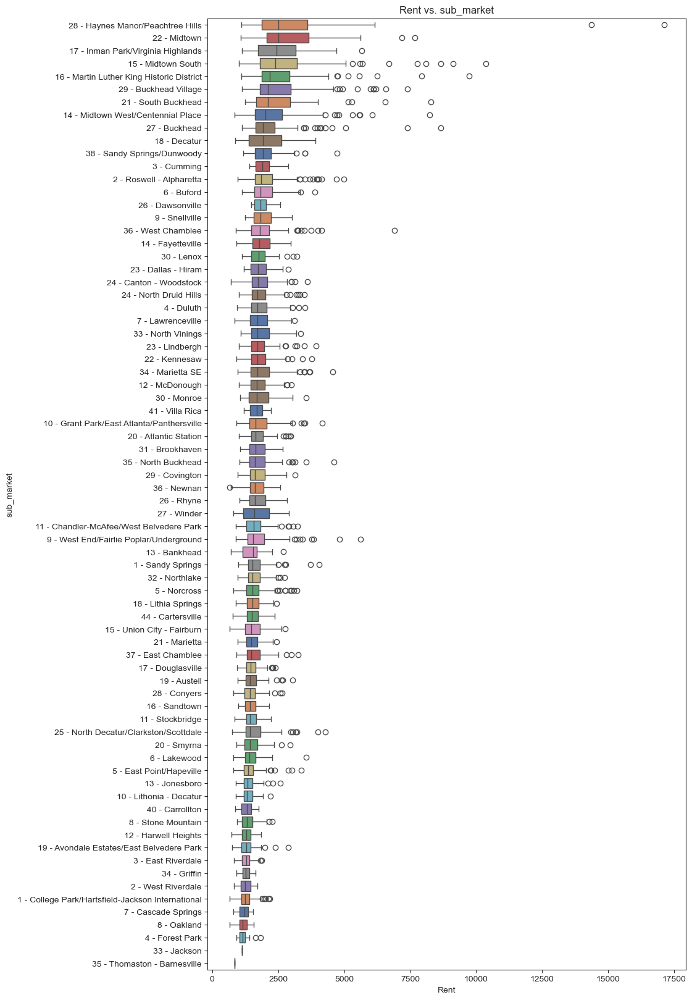

In [19]:
#rent price vs. submarket
plt.figure(figsize=(10, 20))
boxplot('sub_market')

,count,mean,std,min,25%,median,75%,max
county,,,,,,,,
Forsyth,89.0,1943.979614,368.984558,1407.660400,1637.903442,1896.000000,2150.000000,2891.000000
Dawson,15.0,1886.455811,344.376404,1475.000000,1599.833313,1838.663696,2047.670898,2577.852051
Fayette,51.0,1876.080078,440.938538,928.000000,1535.857117,1783.116333,2173.500000,2973.000000
Walton,18.0,1862.171387,640.844116,1067.000000,1481.250000,1761.342102,2128.250000,3549.914307
Cherokee,179.0,1816.952515,455.659698,697.000000,1511.359375,1745.000000,2091.500000,3616.304443
Fulton,2337.0,1998.081055,1057.887329,667.000000,1414.853638,1726.000000,2233.923096,17129.833984
Paulding,40.0,1785.293335,436.651825,1196.000000,1420.750000,1702.736450,2031.332825,2889.787354
Henry,190.0,1749.122192,394.620819,1001.000000,1423.000000,1683.253601,1985.000000,3003.500000
Gwinnett,917.0,1754.880859,467.309052,793.000000,1421.810791,1658.000000,1970.000000,3882.000000


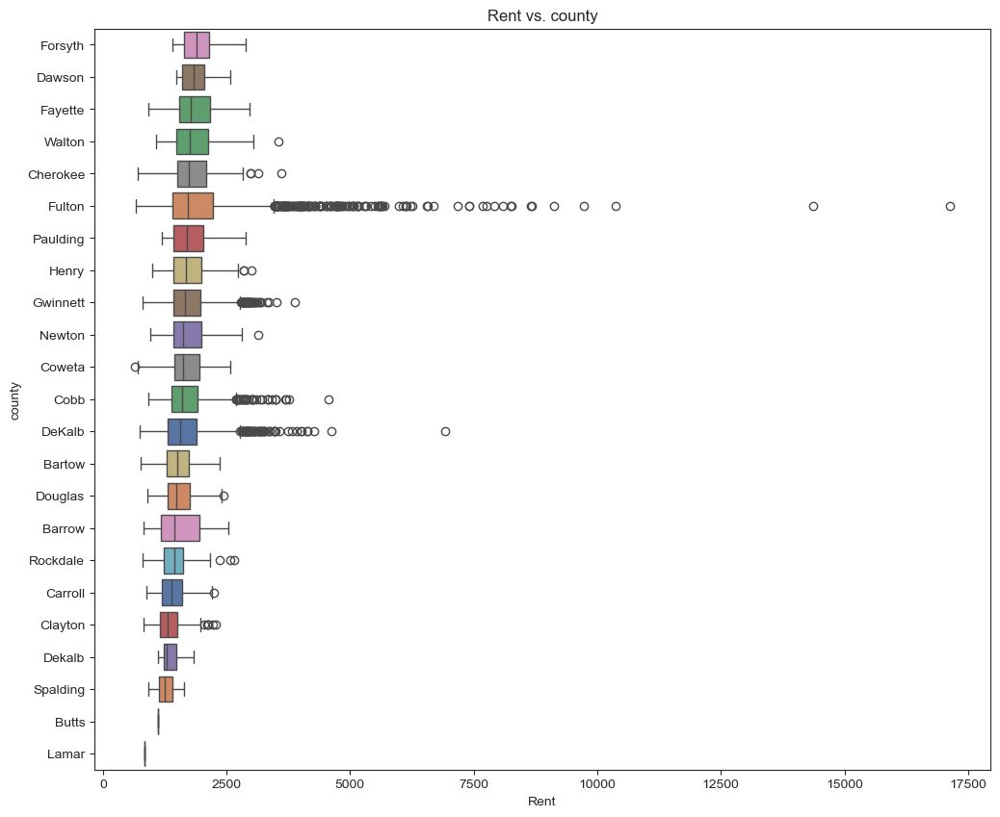

In [20]:
#rent price vs. county
plt.figure(figsize=(12, 10))
boxplot('county')

,count,mean,std,min,25%,median,75%,max
property_quality,,,,,,,,
A+,69.0,3809.266357,2647.741211,1565.00000,2147.100098,2943.010254,4777.250000,17129.833984
A,1258.0,2268.668213,964.126343,1146.00000,1686.810181,2007.304810,2528.361023,10370.333008
A-,1908.0,1936.338135,606.994263,953.08313,1530.779938,1796.000000,2194.000000,8242.000000
B+,1239.0,1653.497681,436.537170,793.00000,1368.500000,1578.750000,1856.500000,5655.000000
B,1181.0,1503.744751,364.773071,799.00000,1257.794556,1451.000000,1674.000000,3821.000000
B-,757.0,1378.924561,318.737854,653.00000,1170.000000,1340.000000,1532.000000,3702.666748
C+,319.0,1293.621460,322.624756,672.00000,1055.000000,1276.000000,1450.000000,2499.000000
C,134.0,1231.228516,245.912354,673.00000,1056.000000,1196.000000,1353.250000,2093.285645
C-,20.0,1164.943970,261.469391,750.00000,995.250000,1117.000000,1273.000000,1766.000000


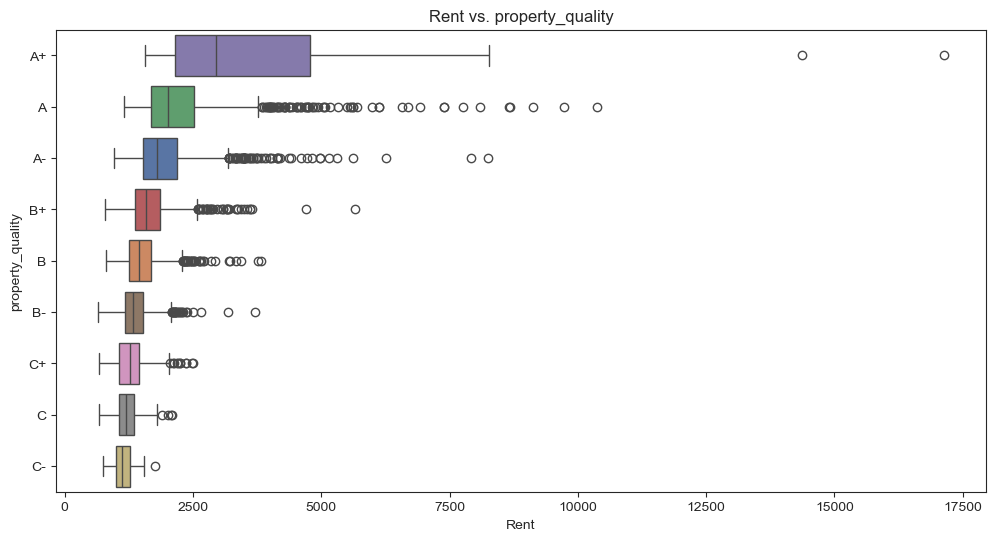

In [21]:
#rent price vs. property quality
plt.figure(figsize=(12, 6))
boxplot('property_quality')

,count,mean,std,min,25%,median,75%,max
location_quality,,,,,,,,
A+,76.0,2484.659180,1291.958374,1099.0,1673.327087,2080.50000,2830.213684,8664.333008
A,529.0,2268.688232,1272.611328,928.0,1650.000000,1960.00000,2405.922607,17129.833984
A-,824.0,2095.979980,925.276611,897.0,1578.244171,1865.33783,2308.096985,10370.333008
B+,906.0,1860.691284,606.422241,872.0,1460.074463,1728.46698,2138.700073,7683.000000
B,1297.0,1855.396729,720.711914,772.0,1427.053711,1696.00000,2094.693848,9730.000000
B-,1479.0,1698.528687,534.591919,667.0,1356.858948,1590.00000,1921.494690,5610.856934
C-,44.0,1433.909912,411.748962,850.0,1146.278992,1397.00000,1610.250000,3014.000000
C+,1404.0,1450.341187,376.873047,653.0,1199.218170,1394.00000,1627.838623,3567.000000
C,318.0,1423.409668,417.923676,672.0,1180.000000,1340.50000,1560.000000,4204.000000


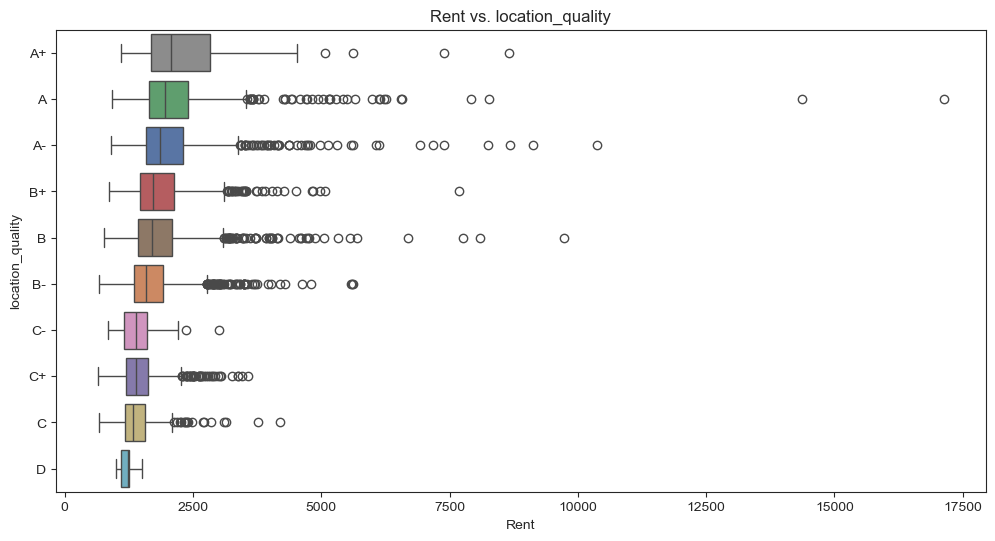

In [22]:
#rent price vs. location quality
plt.figure(figsize=(12, 6))
boxplot('location_quality')

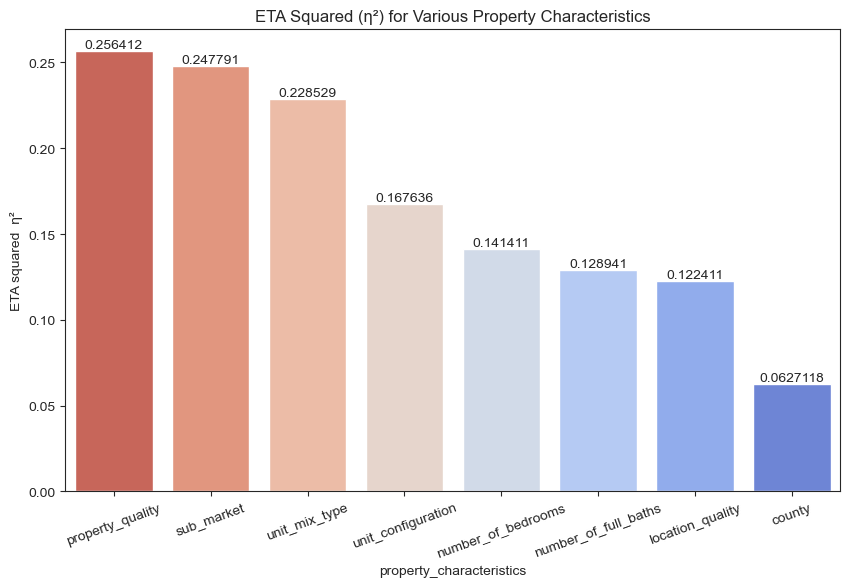

In [23]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

prop_char_cols = [
    'unit_configuration', 'unit_mix_type', 'number_of_bedrooms', 'number_of_full_baths', 'sub_market', 'county', 
    'property_quality', 'location_quality'
]

#using one-way anova, compute eta_squared for each col above
#eta_squared calculates the variance explained by an effect relative to the total variance in the data.
eta_scores = []
for col in prop_char_cols:
    equation = f"rent ~ {col}"
    anova = ols(equation, data=combined_df).fit()
    anova_table = sm.stats.anova_lm(anova, typ=2)
    ss_group = anova_table.loc[col, 'sum_sq']
    ss_total = ss_group + anova_table.loc['Residual', 'sum_sq']
    eta_sq = ss_group / ss_total
    eta_scores.append(eta_sq)

#dictionary combining the two lists
eta_dict = dict(zip(prop_char_cols, eta_scores))
eta_dict = dict(sorted(eta_dict.items(), key=lambda item: item[1], reverse=True))


#plot eta scores
plt.figure(figsize=(10, 6))
barplot = sns.barplot(
        x=list(eta_dict.keys()), y=list(eta_dict.values()), hue=prop_char_cols, palette='coolwarm_r', legend=False)

plt.title("ETA Squared (η²) for Various Property Characteristics")
plt.xlabel("property_characteristics")
plt.ylabel("ETA squared  η²")
plt.xticks(rotation=20)
for container in barplot.containers:
    barplot.bar_label(container)   
plt.show()

**according to Gemini*   
Commonly used rules of thumb for evaluating the effect size:  
η² = 0.01:  Small effect  
η² = 0.06:  Medium effect  
η² = 0.14 or higher:  Large effect

count     6887.000000
mean      1087.476840
std        351.576555
min        276.000000
25%        819.000000
median    1080.000000
75%       1286.000000
max       4263.000000
Name: living_area_square_feet, dtype: float64

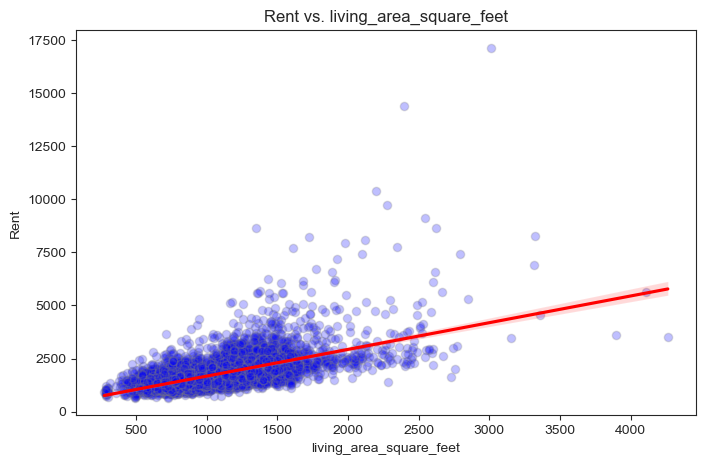

In [24]:
#also explore relationships between rent and 'numerical' property charactersitics

#create scatterplot function
def scatterplot(col):
    sum_stats = combined_df[col].describe()
    sum_stats.rename(
        {'50%': 'median'}, inplace=True)
    display(sum_stats)

    sns.regplot(
        data=combined_df, x=col, y='rent', 
        scatter_kws={"color": "blue", "alpha": 0.25, "edgecolor": "gray"}, line_kws={"color": "red"},)

    plt.title("Rent vs. " + col)
    plt.xlabel(col)
    plt.xticks(rotation=0)
    plt.ylabel("Rent")
    plt.show()


#rent price vs. sqft
plt.figure(figsize=(8, 5))
scatterplot('living_area_square_feet')

count     6887.000000
mean        28.840714
std         19.709458
min         -1.000000
25%          9.000000
median      27.000000
75%         43.000000
max        125.000000
Name: property_age, dtype: float64

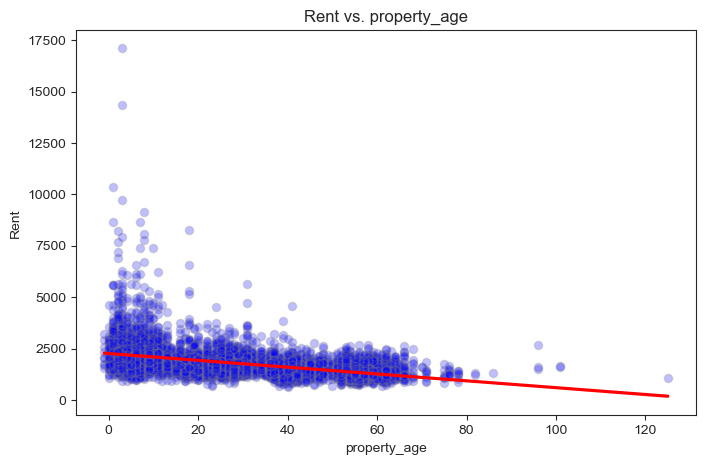

In [25]:
#rent price vs. property age
#create property age feature
combined_df['property_age'] = 2026 - combined_df['year_built']

plt.figure(figsize=(8, 5))
scatterplot('property_age')

*In general rent price decreases with property age, but there are noticible spikes in this scatterplot, suggesting certain periods of time produce high rent prices (ex: around the 20 year mark - 2000's).  


count     6885.000000
mean         4.189833
std          4.447004
min          1.000000
25%          2.000000
median       3.000000
75%          4.000000
max         39.000000
Name: number_of_stories, dtype: float64

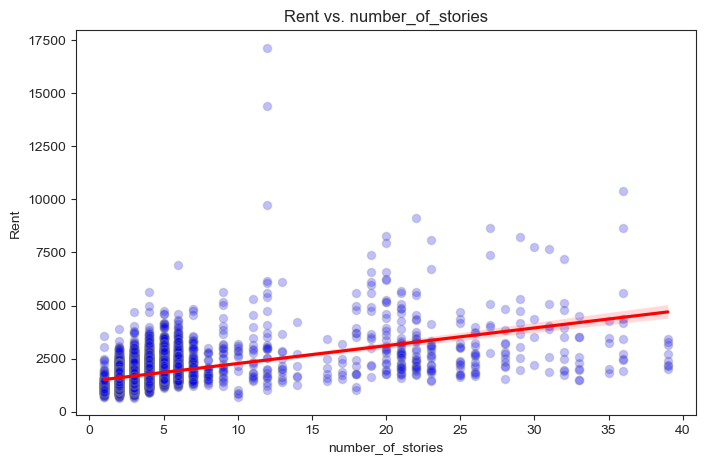

In [26]:
#rent price vs. max stories/min stories
plt.figure(figsize=(8, 5))
scatterplot('number_of_stories')

count     6884.000000
mean        15.060285
std         16.899374
min          1.000000
25%          4.000000
median      11.000000
75%         20.000000
max        331.000000
Name: num_buildings, dtype: float64

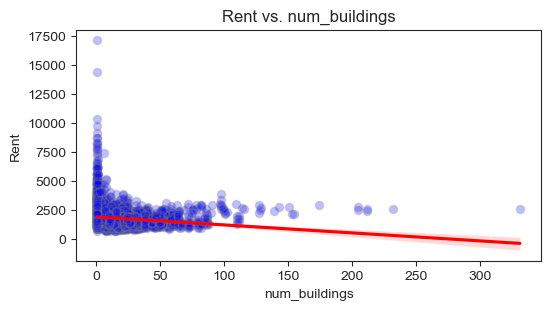

count     6887.000000
mean        75.098882
std         67.119723
min          1.000000
25%         24.000000
median      57.000000
75%        111.000000
max        910.000000
Name: num_units_x, dtype: float64

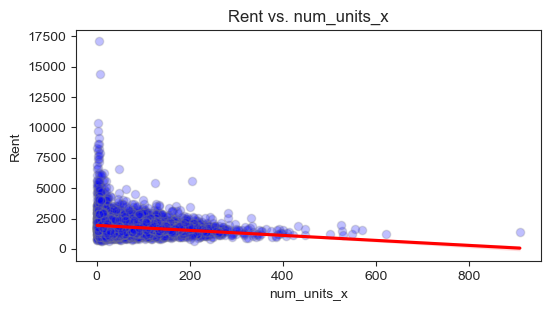

In [27]:
#rent price vs. number of buildings/units
plt.figure(figsize=(6, 3))
scatterplot('num_buildings')

plt.figure(figsize=(6, 3))
scatterplot('num_units_x')

count     6470.000000
mean         0.916894
std          0.088820
min          0.149254
25%          0.905405
median       0.939655
75%          0.962069
max          1.000000
Name: occupancy_rate, dtype: float64

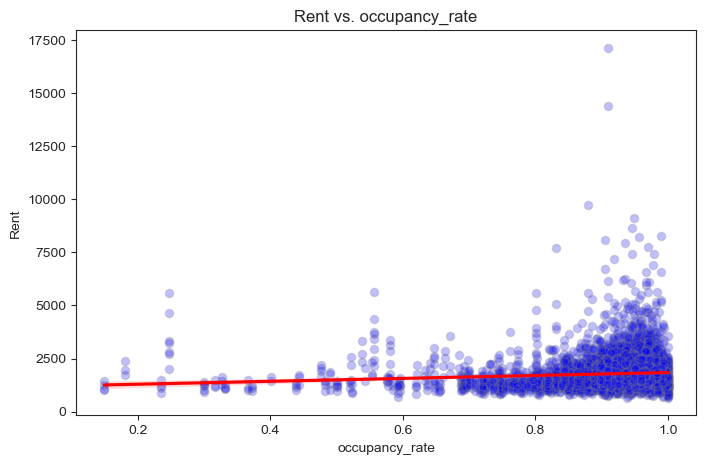

In [28]:
#rent price vs. occupancy rate
plt.figure(figsize=(8, 5))
scatterplot('occupancy_rate')

count     6713.000000
mean       459.128557
std        269.330366
min          0.000000
25%        291.000000
median     420.000000
75%        580.000000
max       3000.000000
Name: total_parking_spaces, dtype: float64

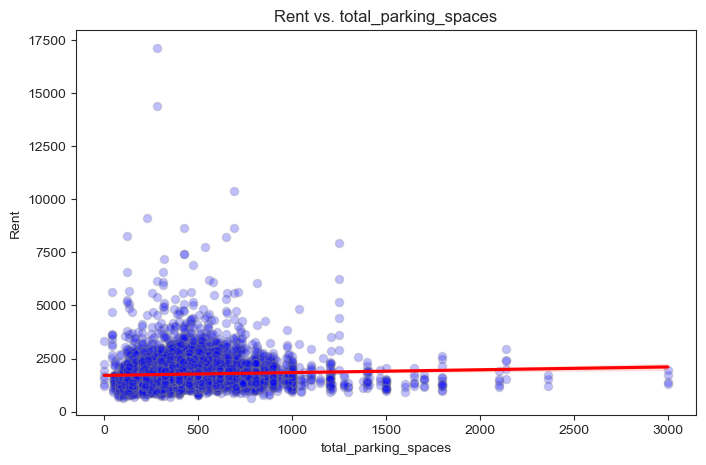

In [29]:
#rent price vs. total_parking_spaces
plt.figure(figsize=(8, 5))
scatterplot('total_parking_spaces')

In [30]:
combined_df.select_dtypes(include=['number']).info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6891 entries, 0 to 6890
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   rent                        6887 non-null   float32
 1   num_units_x                 6887 non-null   float64
 2   living_area_square_feet     6887 non-null   float64
 3   number_of_bedrooms          6887 non-null   float64
 4   number_of_full_baths        6887 non-null   float64
 5   rent_amount                 6887 non-null   float32
 6   longitude                   6887 non-null   float32
 7   latitude                    6887 non-null   float32
 8   num_units_y                 6887 non-null   float64
 9   year_built                  6887 non-null   float64
 10  total_parking_spaces        6713 non-null   float64
 11  min_stories                 6885 non-null   float64
 12  max_stories                 6885 non-null   float64
 13  number_of_stories           6885 

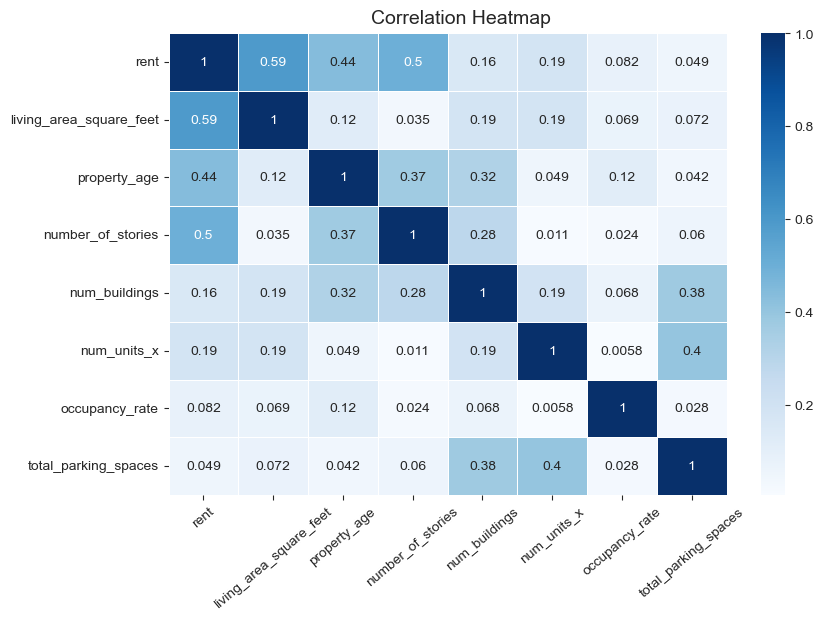

In [31]:
prop_char_cols_2 = [
    'rent', 'living_area_square_feet', 'property_age', 'number_of_stories', 'num_buildings', 'num_units_x', 'occupancy_rate',
    'total_parking_spaces'
]

#correlation heatmap (r)
plt.subplots(figsize=(9, 6))
corr_matrix = combined_df[prop_char_cols_2].corr()
corr_heatmap = sns.heatmap(
        np.abs(corr_matrix), annot=True, cmap='Blues', linewidths=0.5)

corr_heatmap.figure.suptitle('Correlation Heatmap', y=0.92, x=0.45, fontsize=14)
plt.xticks(rotation=40)
plt.show()  

### Amenities

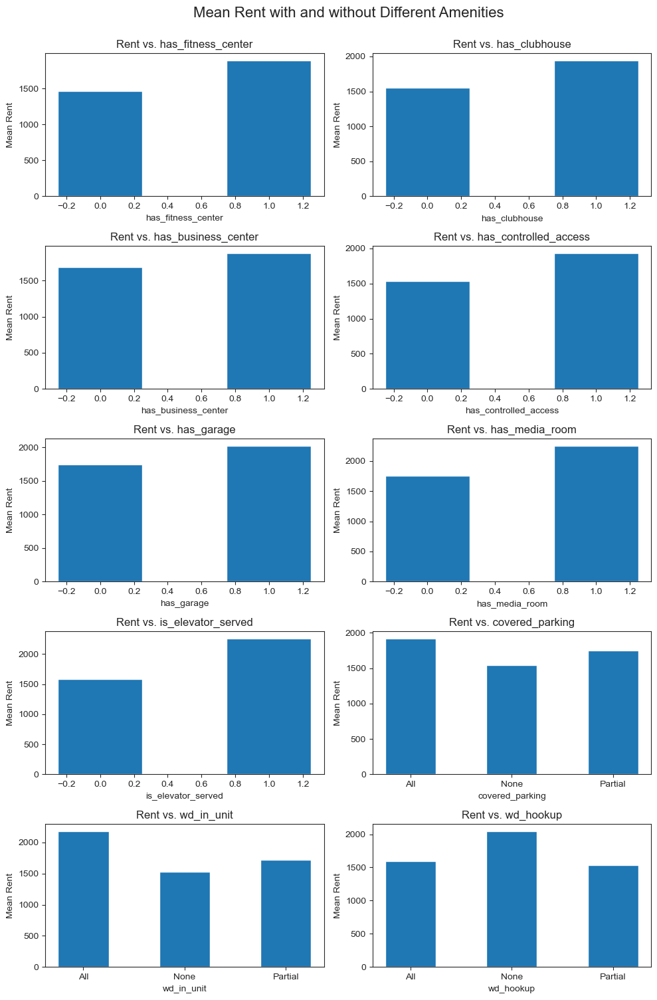

In [32]:
amenities_cols = [
    'has_fitness_center', 'has_clubhouse', 'has_business_center', 'has_controlled_access', 'has_garage', 'has_media_room', 
    'is_elevator_served', 'covered_parking', 'wd_in_unit', 'wd_hookup'
]

#plot avg rent with and without each amenity
fig, axes = plt.subplots(5, 2, figsize=(10, 15))
axes_flat = axes.flatten()
for i, col in enumerate(amenities_cols):
    ax = axes_flat[i]
    ax.bar(
        x=combined_df.groupby(col)['rent'].mean().index, height=combined_df.groupby(col)['rent'].mean(), width=0.5)
    ax.set_title(f"Rent vs. {col}")
    ax.set_ylabel("Mean Rent")
    ax.set_xlabel(f"{col}")

fig.suptitle("Mean Rent with and without Different Amenities", x=0.53, y=1, fontsize=16)
plt.tight_layout()
plt.show()

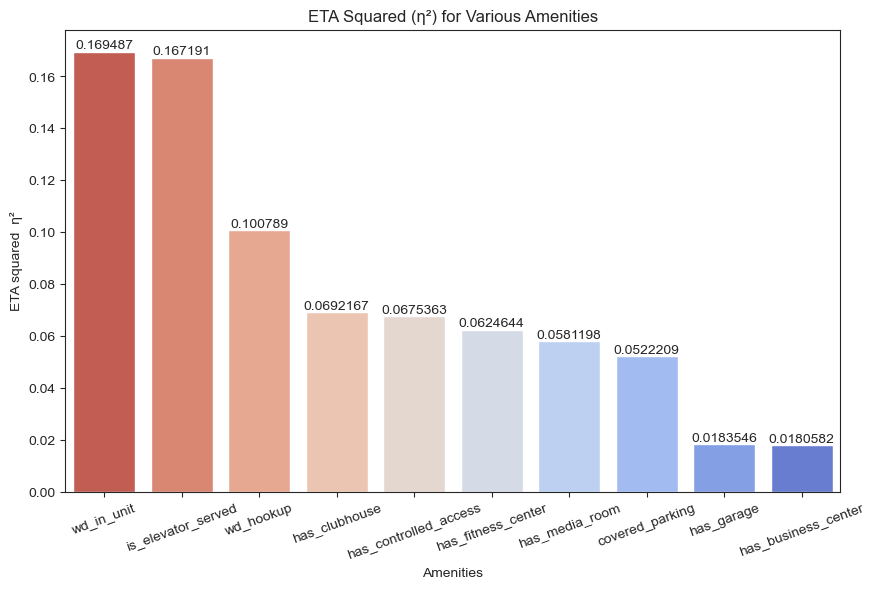

In [33]:
#correlation between amenities cols and rent price using eta squared
#for the binary columns, eta squared and r sqaured are identical values
eta_scores_2 = []
for col in amenities_cols:
    equation = f"rent ~ {col}"
    anova = ols(equation, data=combined_df).fit()
    anova_table = sm.stats.anova_lm(anova, typ=2)
    ss_group = anova_table.loc[col, 'sum_sq']
    ss_total = ss_group + anova_table.loc['Residual', 'sum_sq']
    eta_sq = ss_group / ss_total
    eta_scores_2.append(eta_sq)

#dictionary
eta_dict_2 = dict(zip(amenities_cols, eta_scores_2))
eta_dict_2 = dict(sorted(eta_dict_2.items(), key=lambda item: item[1], reverse=True))


#plot eta scores
plt.figure(figsize=(10, 6))
barplot = sns.barplot(
        x=list(eta_dict_2.keys()), y=list(eta_dict_2.values()), hue=amenities_cols, palette='coolwarm_r', legend=False)

plt.title("ETA Squared (η²) for Various Amenities")
plt.xlabel("Amenities")
plt.ylabel("ETA squared  η²")
plt.xticks(rotation=20)
for container in barplot.containers:
    barplot.bar_label(container)   
plt.show()

**according to Gemini*   
Commonly used rules of thumb for evaluating the effect size:  
η² = 0.01:  Small effect  
η² = 0.06:  Medium effect  
η² = 0.14 or higher:  Large effect

In [34]:
from scipy.stats import chi2_contingency

#check for potential correlation between amenities and property_quality (multicolinearity)
p_values = {}
for col in amenities_cols:
    table = pd.crosstab(combined_df[col], combined_df['property_quality'])
    chi2, p_value, dof, expected = chi2_contingency(table)
    p_values[col] = p_value

p_values

{'has_fitness_center': 0.0,
 'has_clubhouse': 0.0,
 'has_business_center': 7.7891442297587e-311,
 'has_controlled_access': 0.0,
 'has_garage': 1.8672223421415895e-149,
 'has_media_room': 5.270058889252454e-40,
 'is_elevator_served': 0.0,
 'covered_parking': 7.744994793811622e-184,
 'wd_in_unit': 0.0,
 'wd_hookup': 0.0}

*All these p-values are way below the 0.05 threshold, meaning there is significant evidence for multicolinearity between property quality grades and amenities. This makes the amenities features slightly (but not completely) redundant.  


### Geospatial

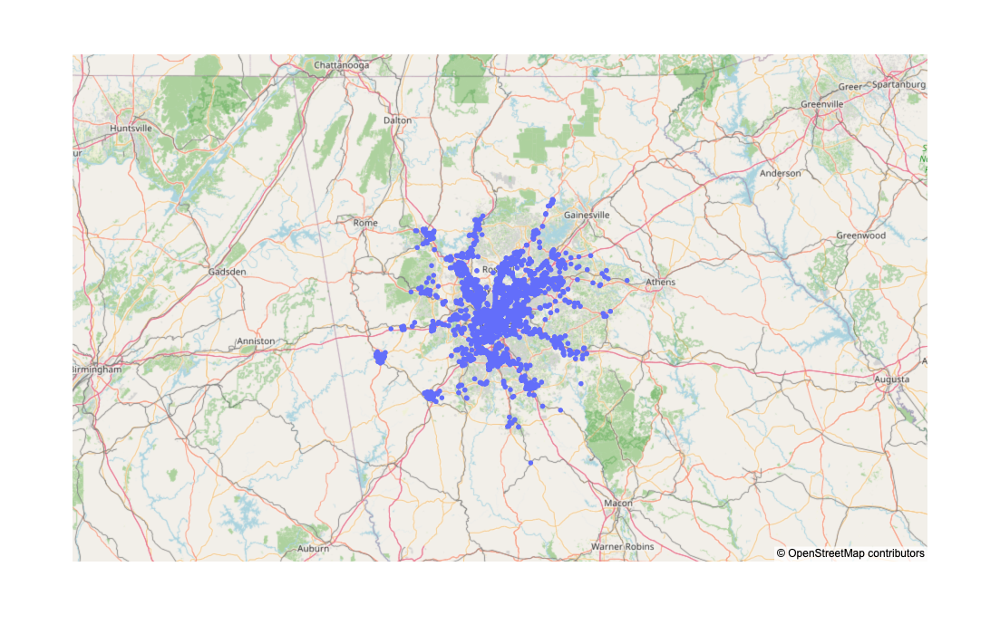

In [35]:
import plotly.express as px

#map out latitude/longitude points
map = px.scatter_mapbox(combined_df, lat="latitude", lon="longitude", hover_name='city',
                        zoom=7, height=700)

map.update_layout(mapbox_style="open-street-map")
map.show()

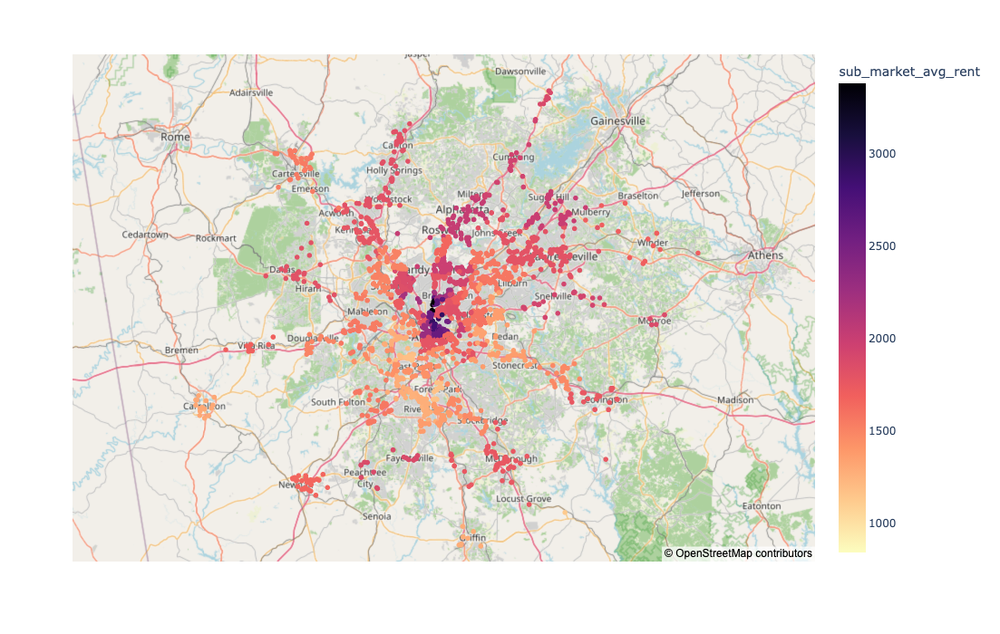

In [36]:
#color based on submarket mean rent

#create submarket avg rent column
combined_df['sub_market_avg_rent'] = combined_df.groupby('sub_market')['rent'].transform('mean')

map = px.scatter_mapbox(combined_df, lat="latitude", lon="longitude", hover_name='sub_market',
                        zoom=8, height=700, color='sub_market_avg_rent', color_continuous_scale='magma_r')

map.update_layout(mapbox_style="open-street-map")
map.show()

In [37]:
#read in landmarks file
landmarks_df = pd.read_csv("/Users/njlim21/Desktop/forty5park/vignette/01_geospatial_expansion/data/atlanta_landmarks.csv")
landmarks_df

,key,name,type,latitude,longitude,source
0,buckhead,Buckhead,neighborhood,33.839420,-84.379920,https://en.wikipedia.org/wiki/Buckhead
1,midtown,Midtown Atlanta,neighborhood,33.786801,-84.379517,https://en.wikipedia.org/wiki/Midtown_Atlanta
2,downtown,Downtown Atlanta,cbd,33.755000,-84.390000,https://en.wikipedia.org/wiki/Downtown_Atlanta
3,atl_airport,Hartsfield-Jackson Atlanta International Airport,airport,33.640700,-84.427700,https://en.wikipedia.org/wiki/Hartsfield-Jacks...


In [38]:
#add landmarks_df lat/lon data to combined_df
for i in range(len(landmarks_df)):
    lat = landmarks_df.loc[i, 'latitude']
    lon = landmarks_df.loc[i, 'longitude']
    combined_df[f"{landmarks_df.loc[i, 'key']}_lat"] = lat
    combined_df[f"{landmarks_df.loc[i, 'key']}_lon"] = lon

In [39]:
import math

#create function to compute distance (in miles) between two lat/lon points
def haversine_miles(lat1, lon1, lat2, lon2):
    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = pd.Series([lat1, lon1, lat2, lon2]) * (math.pi / 180)
    
    # Differences
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    # Haversine formula
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    # 3959 miles is the approximate radius of the Earth
    miles = 3959 * c
    return miles

In [40]:
#apply distance function to create 'distance to landmark' features
landmark_cols = landmarks_df['key'].tolist()
for i in landmark_cols:
    combined_df[f"distance_to_{i}"] = haversine_miles(
            combined_df["latitude"], combined_df["longitude"], combined_df[f"{i}_lat"], combined_df[f"{i}_lon"]
)    

In [41]:
landmark_dist_cols = combined_df.filter(like='distance', axis=1).columns.tolist()
combined_df[landmark_dist_cols]

,distance_to_buckhead,distance_to_midtown,distance_to_downtown,distance_to_atl_airport
0,6.971485,10.478095,12.753468,20.937695
1,6.971485,10.478095,12.753468,20.937695
2,6.971485,10.478095,12.753468,20.937695
3,6.971485,10.478095,12.753468,20.937695
4,6.896762,10.421326,12.694746,20.875448
...,...,...,...,...
6886,27.597516,23.982383,21.890867,14.837625
6887,27.597516,23.982383,21.890867,14.837625
6888,27.597516,23.982383,21.890867,14.837625
6889,27.597516,23.982383,21.890867,14.837625


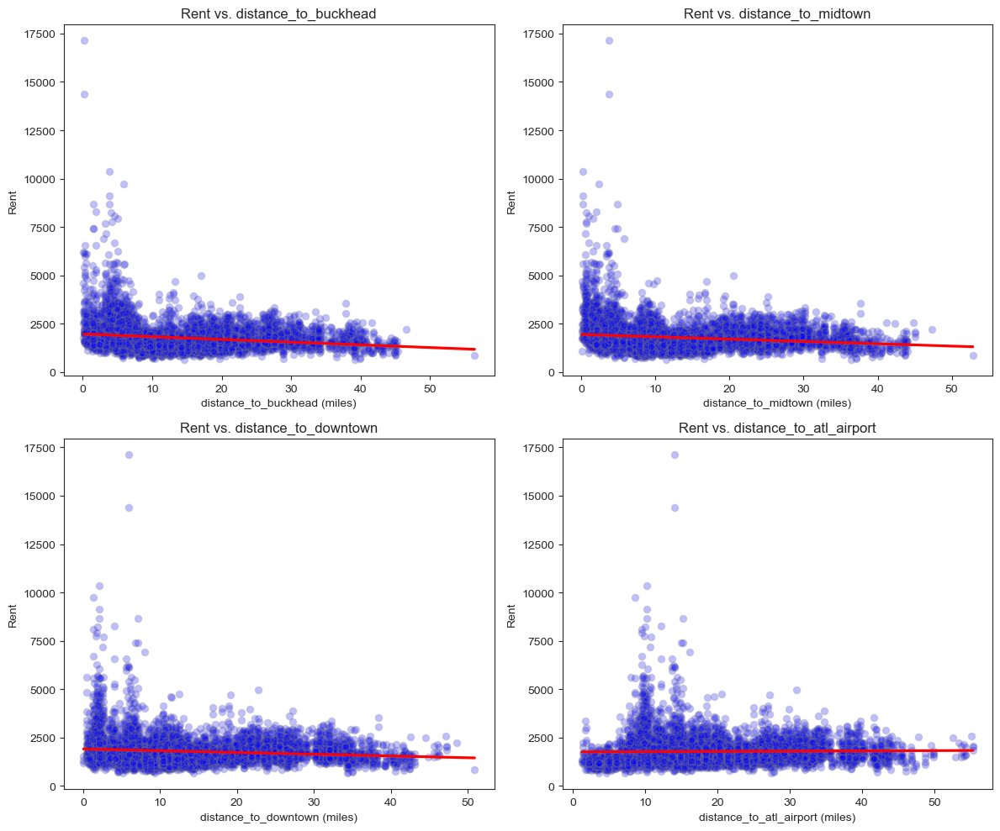

In [42]:
#plot rent vs. distance to landmark
fig, axes = plt.subplots(2, 2, figsize=(12,10))
axes_flat = axes.flatten()
for i, col in enumerate(landmark_dist_cols):
    ax = axes_flat[i]
    sns.regplot(
        data=combined_df, x=col, y='rent', 
        scatter_kws={"color": "blue", "alpha": 0.25, "edgecolor": "gray"}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"Rent vs. {col}")
    ax.set_ylabel("Rent")
    ax.set_xlabel(f"{col} (miles)")

plt.tight_layout()
plt.show()

In [43]:
#add/test new landmark: Five Points Station --> (33.753826° N, 84.391571° W)
landmarks_df.loc[len(landmarks_df)] = {
    'key': 'five_points_station', 
    'name': 'Five Points Station', 
    'type': 'transportation',
    'latitude': 33.753826,
    'longitude': -84.391571
}

landmarks_df

,key,name,type,latitude,longitude,source
0,buckhead,Buckhead,neighborhood,33.839420,-84.379920,https://en.wikipedia.org/wiki/Buckhead
1,midtown,Midtown Atlanta,neighborhood,33.786801,-84.379517,https://en.wikipedia.org/wiki/Midtown_Atlanta
2,downtown,Downtown Atlanta,cbd,33.755000,-84.390000,https://en.wikipedia.org/wiki/Downtown_Atlanta
3,atl_airport,Hartsfield-Jackson Atlanta International Airport,airport,33.640700,-84.427700,https://en.wikipedia.org/wiki/Hartsfield-Jacks...
4,five_points_station,Five Points Station,transportation,33.753826,-84.391571,NaN


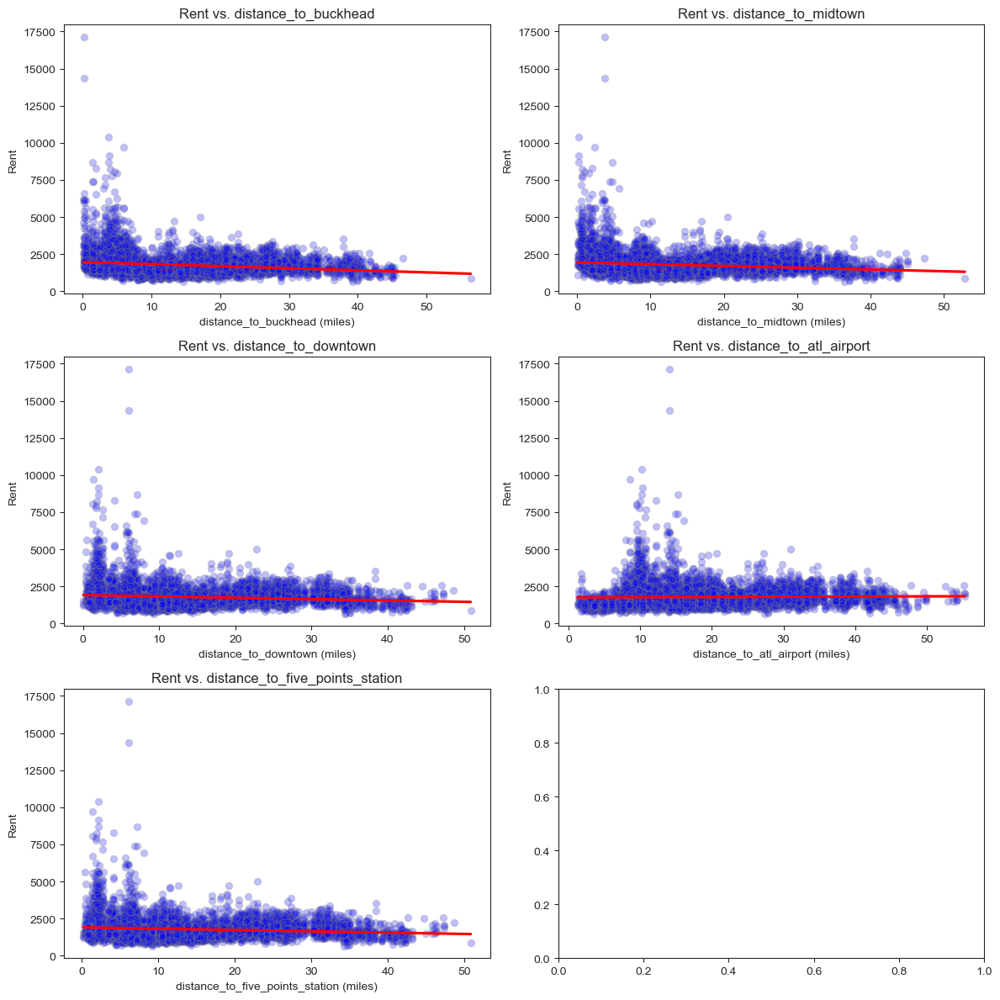

In [44]:
#rerun code
for i in range(len(landmarks_df)):
    lat = landmarks_df.loc[i, 'latitude']
    lon = landmarks_df.loc[i, 'longitude']
    combined_df[f"{landmarks_df.loc[i, 'key']}_lat"] = lat
    combined_df[f"{landmarks_df.loc[i, 'key']}_lon"] = lon

landmark_cols = landmarks_df['key'].tolist()
for i in landmark_cols:
    combined_df[f"distance_to_{i}"] = haversine_miles(
            combined_df["latitude"], combined_df["longitude"], combined_df[f"{i}_lat"], combined_df[f"{i}_lon"]
) 

#replot
landmark_dist_cols = combined_df.filter(like='distance', axis=1).columns.tolist()
fig, axes = plt.subplots(3, 2, figsize=(12,12))
axes_flat = axes.flatten()
for i, col in enumerate(landmark_dist_cols):
    ax = axes_flat[i]
    sns.regplot(
        data=combined_df, x=col, y='rent', 
        scatter_kws={"color": "blue", "alpha": 0.25, "edgecolor": "gray"}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"Rent vs. {col}")
    ax.set_ylabel("Rent")
    ax.set_xlabel(f"{col} (miles)")

plt.tight_layout()
plt.show()

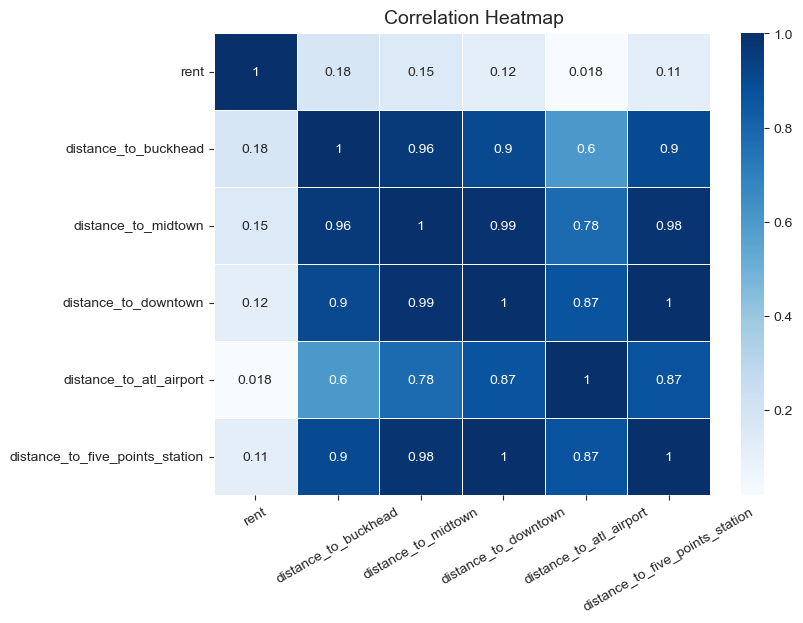

In [45]:
landmark_dist_cols_2 = [
    'rent', 'distance_to_buckhead', 'distance_to_midtown', 'distance_to_downtown', 
    'distance_to_atl_airport', 'distance_to_five_points_station'
]

#correlation matrix
plt.subplots(figsize=(8, 6))
corr_matrix_2 = combined_df[landmark_dist_cols_2].corr()
corr_heatmap = sns.heatmap(
        np.abs(corr_matrix_2), annot=True, cmap='Blues', linewidths=0.5)

corr_heatmap.figure.suptitle('Correlation Heatmap', y=0.92, x=0.45, fontsize=14)
plt.xticks(rotation=30)
plt.show()  

## Rent vs. Historical Data

In [46]:
hist_rent_df

,property_id,unit_mix_type,unit_garage,unit_type,period,rent,date
0,22_1004844,None,NaN,1BR,2015-01-01,1080.774170,2026-04-20
1,22_1004844,None,NaN,1BR,2015-02-01,1138.064575,2026-04-20
2,22_1004844,None,NaN,1BR,2015-03-01,1127.903198,2026-04-20
3,22_1004844,None,NaN,1BR,2015-04-01,1117.741943,2026-04-20
4,22_1004844,None,NaN,1BR,2015-05-01,1107.580688,2026-04-20
...,...,...,...,...,...,...,...
708820,24_99,Apartment,0.0,1BR,2026-03-01,1467.444458,2026-04-20
708821,24_99,Apartment,0.0,2BR/2Bath,2026-03-01,1582.850464,2026-04-20
708822,24_99,Apartment,0.0,3BR+,2026-03-01,1865.000000,2026-04-20
708823,24_99,Apartment,1.0,1BR,2026-03-01,1508.000000,2026-04-20


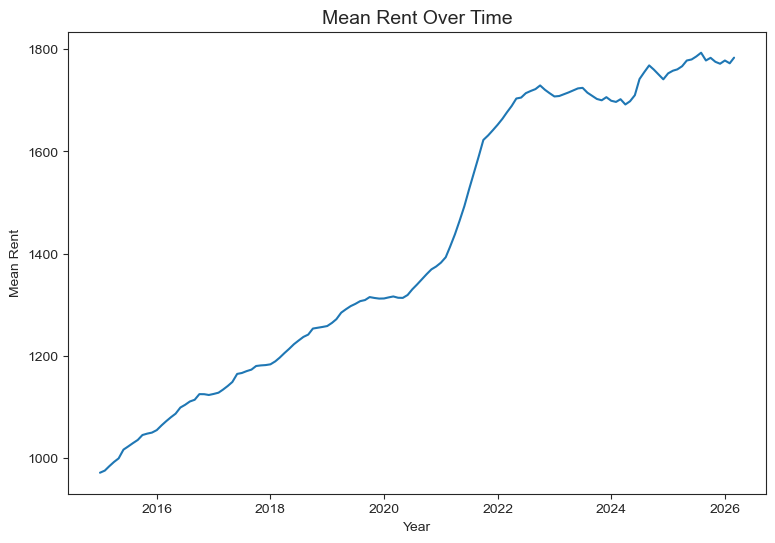

In [76]:
#overall rent over time
plt.subplots(figsize=(9, 6))
hist_rent_df.groupby('period')['rent'].mean().plot(kind='line')

plt.title("Mean Rent Over Time", fontsize=14)
plt.xlabel("Year")
plt.ylabel("Mean Rent")
plt.show()

In [47]:
import random

#select five random properties to explore
sample_properties = hist_rent_df[['property_id', 'unit_type']].sample(n=5, random_state=0).reset_index()
sample_properties

,index,property_id,unit_type
0,166217,22_673734,Studio
1,343872,24_3982,2BR/2Bath
2,644110,24_1357396,3BR+
3,295063,24_2798,2BR/2Bath
4,501827,22_3208,Studio


In [60]:
#filter data to only include sample properties
samples_df = hist_rent_df[
        (
            (hist_rent_df['property_id'] == sample_properties.loc[0, 'property_id']) & 
            (hist_rent_df['unit_type'] == sample_properties.loc[0, 'unit_type'])
    ) | (
            (hist_rent_df['property_id'] == sample_properties.loc[1, 'property_id']) & 
            (hist_rent_df['unit_type'] == sample_properties.loc[1, 'unit_type'])
    ) | (
            (hist_rent_df['property_id'] == sample_properties.loc[2, 'property_id']) & 
            (hist_rent_df['unit_type'] == sample_properties.loc[2, 'unit_type'])
    ) | (
            (hist_rent_df['property_id'] == sample_properties.loc[3, 'property_id']) & 
            (hist_rent_df['unit_type'] == sample_properties.loc[3, 'unit_type'])
    ) | (
            (hist_rent_df['property_id'] == sample_properties.loc[4, 'property_id']) & 
            (hist_rent_df['unit_type'] == sample_properties.loc[4, 'unit_type']))
]

samples_df = samples_df.sort_values(by=['property_id', 'period'])
samples_df

,property_id,unit_mix_type,unit_garage,unit_type,period,rent,date
48264,22_3208,None,NaN,Studio,2015-01-01,1041.827637,2026-04-20
48265,22_3208,None,NaN,Studio,2015-02-01,1047.758667,2026-04-20
48266,22_3208,None,NaN,Studio,2015-03-01,1062.137939,2026-04-20
48267,22_3208,None,NaN,Studio,2015-04-01,1076.517212,2026-04-20
48268,22_3208,None,NaN,Studio,2015-05-01,1090.896606,2026-04-20
...,...,...,...,...,...,...,...
685430,24_3982,Apartment,0.0,2BR/2Bath,2025-11-01,1340.423096,2026-04-20
685431,24_3982,Apartment,0.0,2BR/2Bath,2025-12-01,1345.000000,2026-04-20
693667,24_3982,Apartment,0.0,2BR/2Bath,2026-01-01,1346.615356,2026-04-20
700546,24_3982,Apartment,0.0,2BR/2Bath,2026-02-01,1369.461548,2026-04-20


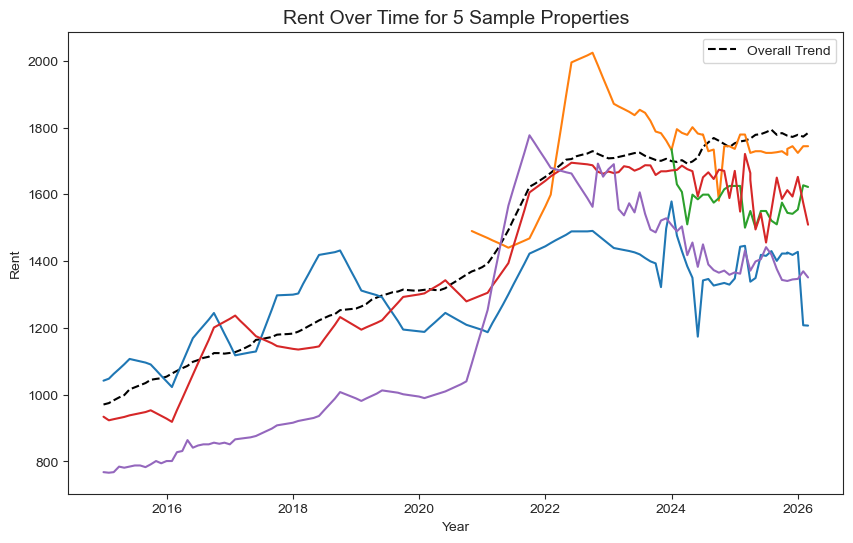

In [90]:
#plot rent over time for the sample properties
plt.figure(figsize=(10, 6))

#compare to overall trend
hist_rent_df.groupby('period')['rent'].mean().plot(kind='line', linestyle='dashed', color='black')

for i in samples_df['property_id'].unique():
    plt.plot(
        samples_df[samples_df['property_id'] == i]['period'], 
        samples_df[samples_df['property_id'] == i]['rent'])

plt.title("Rent Over Time for 5 Sample Properties", fontsize=14)
plt.xlabel("Year")
plt.ylabel("Rent")
plt.legend(['Overall Trend']) 
plt.show()

### Previous Rent Effect (Autocorrelation)

In [56]:
#select one random property to explore
sample_property = hist_rent_df[['property_id', 'unit_type']].sample(n=1, random_state=0).reset_index()
sample_df = hist_rent_df[
                (hist_rent_df['property_id'] == sample_property.loc[0, 'property_id']) & 
                (hist_rent_df['unit_type'] == sample_property.loc[0, 'unit_type'])
]

sample_df = sample_df.drop_duplicates(subset=['period'])

In [91]:
#create 'previous rent' features
for i in [1, 3, 6, 12, 24]:
    sample_df[f"t-{i} rent"] = sample_df['rent'].shift(i)
sample_df.head(15)

,property_id,unit_mix_type,unit_garage,unit_type,period,rent,date,t-1 rent,t-3 rent,t-6 rent,t-12 rent,t-24 rent
166205,22_673734,None,NaN,Studio,2020-11-01,1490.0,2026-04-20,NaN,NaN,NaN,NaN,NaN
166206,22_673734,None,NaN,Studio,2020-12-01,1483.0,2026-04-20,1490.0,NaN,NaN,NaN,NaN
166207,22_673734,None,NaN,Studio,2021-01-01,1476.0,2026-04-20,1483.0,NaN,NaN,NaN,NaN
166208,22_673734,None,NaN,Studio,2021-02-01,1469.0,2026-04-20,1476.0,1490.0,NaN,NaN,NaN
166209,22_673734,None,NaN,Studio,2021-03-01,1462.0,2026-04-20,1469.0,1483.0,NaN,NaN,NaN
166210,22_673734,None,NaN,Studio,2021-04-01,1455.0,2026-04-20,1462.0,1476.0,NaN,NaN,NaN
166211,22_673734,None,NaN,Studio,2021-05-01,1448.0,2026-04-20,1455.0,1469.0,1490.0,NaN,NaN
166212,22_673734,None,NaN,Studio,2021-06-01,1440.0,2026-04-20,1448.0,1462.0,1483.0,NaN,NaN
166213,22_673734,None,NaN,Studio,2021-07-01,1447.0,2026-04-20,1440.0,1455.0,1476.0,NaN,NaN
166214,22_673734,None,NaN,Studio,2021-08-01,1454.0,2026-04-20,1447.0,1448.0,1469.0,NaN,NaN


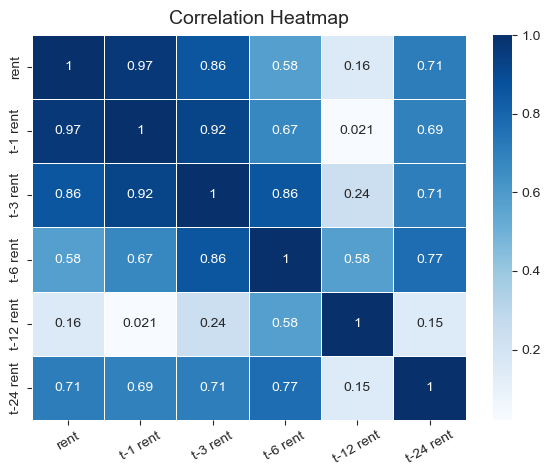

In [92]:
#correlation between current rent and previous rent
time_cols = [
    'rent', 't-1 rent', 't-3 rent', 't-6 rent', 't-12 rent', 't-24 rent'
]

#correlation matrix
plt.subplots(figsize=(7, 5))
corr_matrix_3 = sample_df[time_cols].corr()
corr_heatmap = sns.heatmap(
        np.abs(corr_matrix_3), annot=True, cmap='Blues', linewidths=0.5)

corr_heatmap.figure.suptitle('Correlation Heatmap', y=0.93, x=0.45, fontsize=14)
plt.xticks(rotation=30)
plt.show()  

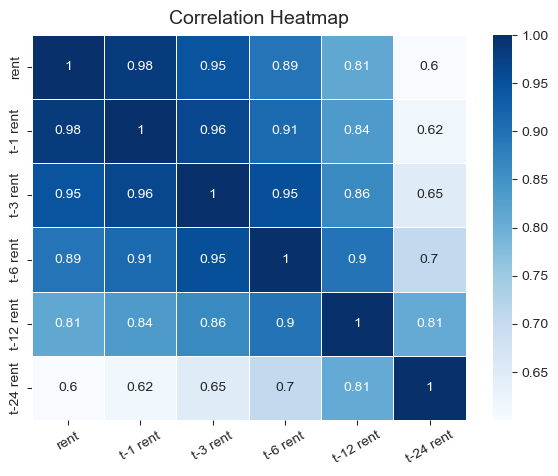

In [93]:
#test on one more property
sample_property_2 = hist_rent_df[['property_id', 'unit_type']].sample(n=1, random_state=1).reset_index()

sample_df_2 = hist_rent_df[
                (hist_rent_df['property_id'] == sample_property_2.loc[0, 'property_id']) & 
                (hist_rent_df['unit_type'] == sample_property_2.loc[0, 'unit_type'])
]

sample_df_2 = sample_df_2.drop_duplicates(subset=['period'])

for i in [1, 3, 6, 12, 24]:
    sample_df_2[f"t-{i} rent"] = sample_df_2['rent'].shift(i)


time_cols_2 = [
    'rent', 't-1 rent', 't-3 rent', 't-6 rent', 't-12 rent', 't-24 rent'
]

plt.subplots(figsize=(7, 5))
corr_matrix_4 = sample_df_2[time_cols_2].corr()
corr_heatmap = sns.heatmap(
        np.abs(corr_matrix_4), annot=True, cmap='Blues', linewidths=0.5)

corr_heatmap.figure.suptitle('Correlation Heatmap', y=0.93, x=0.45, fontsize=14)
plt.xticks(rotation=30)
plt.show()  